In [1]:
import os
import sys 
import glob
import pickle
import numpy as np 
REPO = os.path.abspath('..')
sys.path.insert(0, REPO)

import lib_phmm.profile_hmm as phmm

from collections import defaultdict

In [2]:
HANDLER_STATE      = os.path.join(REPO, 'motif', 'handler_state')
EMBEDDINGS_DIR     = os.path.join(HANDLER_STATE, 'motif_embeddings_cache') 
EMBEDDINGS_VERSION = 'v2'
MODEL_PATH         = os.path.join(HANDLER_STATE, 'motif_extend_state', 'phmm_extended_cluster_mode.pkl')
AUDIO_ROOT         = '/Users/dkohlsdorf/Documents/audio/wdp_data_at_google'   # searched recursively for .wav / .m4a
FMAX_HZ            = 30000                                                 # spectrogram y-limit (whistles sit below ~25 kHz); None = Nyquist

In [3]:
with open(MODEL_PATH, 'rb') as f:
    model_record = pickle.load(f)
hmm = model_record['hmm']
print(f"model: {model_record['n_models']} sub-models, cap {model_record['n_match_states']}")

model: 694 sub-models, cap 20


In [4]:
embeddings, labels, names = [], [], []
for file_name in sorted(os.listdir(EMBEDDINGS_DIR)):
    if file_name.endswith(f'.{EMBEDDINGS_VERSION}.pkl') and not file_name.startswith('noise_embeddings'):
        with open(f"{EMBEDDINGS_DIR}/{file_name}", 'rb') as f:
            emb, classifications, step_samples, emb_sr = pickle.load(f)
            embeddings.append(np.asarray(emb))
            labels.append(np.asarray(classifications))   # per-frame NOISE / ECHO / BURST / UP / DOWN
            names.append(file_name[:-len(f'.{EMBEDDINGS_VERSION}.pkl')])
STEP_SECONDS = step_samples / emb_sr
print(f"{len(embeddings)} recordings, {sum(len(e) for e in embeddings)} frames, {STEP_SECONDS * 1000:.0f} ms per frame")

# the packaged noise recording extend mode's find uses (serverless/runpod_worker/assets/naive_noise.wav),
# embedded by build_noise_model() and cached as (embeddings, step_samples) under the handler's
# NOISE_EMBEDDINGS_CACHE_NAME
with open(f"{EMBEDDINGS_DIR}/noise_embeddings.v2.pkl", 'rb') as f:
    noise_embeddings, _ = pickle.load(f)
noise_embeddings = np.asarray(noise_embeddings)
print(f"noise model fit from {len(noise_embeddings)} frames")

def find_files(root, name):
    return sorted(glob.glob(os.path.join(glob.escape(root), '**', name), recursive=True))

# recording name -> audio path (wav preferred over m4a), as in motif_filtering.ipynb
audio_index = {}
for ext in ('m4a', 'wav'):
    for p in find_files(AUDIO_ROOT, '*.' + ext):
        audio_index[os.path.splitext(os.path.basename(p))[0]] = p
missing = [n for n in names if n not in audio_index]
if missing:
    print(f'WARNING: no audio under {AUDIO_ROOT} for: {missing}')

81 recordings, 1783513 frames, 58 ms per frame
noise model fit from 106947 frames


In [5]:
import os
import pickle
from collections import Counter
from functools import reduce

import numpy as np
from joblib import Parallel, delayed
from sklearn.mixture import BayesianGaussianMixture

import lib_phmm.profile_hmm as phmm
from lib_phmm.phmm_utils import dwell_to_prior_mean


MATCH_STATE = phmm.MATCH_STATE
B = int(phmm.FlankState.B)
# background states: emit through the noise model when viterbi() gets one, silent otherwise
NOISE_STATES = [int(phmm.FlankState.N), int(phmm.FlankState.J), int(phmm.FlankState.C)]
VAR_FLOOR = 0.1  # same floor compress()/make_hmm()/build_noise_model() apply


# ---------------------------------------------------------------- noise model / decode setup

def fit_noise_model(embeddings, n_components=6, var_floor=VAR_FLOOR, var_scale=1.0, seed=0):
    """
    Same fit as build_noise_model(..., n_components, bayesian=True, var_scale),
    which is what find runs in find and extend mode (handler defaults:
    noise_components=6, noise_var_scale=1.0), from already-embedded noise.
    """
    gmm = BayesianGaussianMixture(n_components=n_components, covariance_type='diag',
                                  init_params='k-means++',
                                  weight_concentration_prior_type='dirichlet_process',
                                  random_state=seed).fit(embeddings)
    active = gmm.weights_ > 1e-3
    components = [phmm.Gaussian(gmm.means_[i], np.maximum(gmm.covariances_[i], var_floor) * var_scale)
                  for i in range(n_components) if active[i]]
    return phmm.MixtureModel(components, np.log(gmm.weights_[active]).tolist())


def noise_params(noise_pdf):
    """(means, variances, log_weights) arrays of a MixtureModel's diagonal Gaussian components."""
    components, log_weights = noise_pdf.__getstate__()
    means, variances = zip(*(c.__getstate__() for c in components))
    return (np.asarray(means, dtype=np.float64), np.asarray(variances, dtype=np.float64),
            np.asarray(log_weights, dtype=np.float64))


def copy_hmm(hmm):
    return pickle.loads(pickle.dumps(hmm))


def with_search_transitions(hmm, repeat_prob=0.999, gap_dwell_frames=100.0):
    """Copy of hmm with find's ec/ej/jj/jb overrides (motif_discovery.apply_search_transitions)."""
    hmm = copy_hmm(hmm)
    jj = dwell_to_prior_mean(gap_dwell_frames)
    hmm.trans.ej = np.log2(repeat_prob)
    hmm.trans.ec = np.log2(1.0 - repeat_prob)
    hmm.trans.jj = np.log2(jj)
    hmm.trans.jb = np.log2(1.0 - jj)
    return hmm


# ---------------------------------------------------------------- map

def summarize(keys, x):
    """Per distinct key: (count, mean, M2) of the rows of x carrying it, as {key: value} dicts."""
    ids, inv = np.unique(keys, return_inverse=True)
    counts = np.bincount(inv, minlength=len(ids)).astype(np.float64)
    sums = np.zeros((len(ids), x.shape[1]))
    np.add.at(sums, inv, x)
    means = sums / counts[:, None]
    M2 = np.zeros_like(sums)
    np.add.at(M2, inv, np.square(x - means[inv]))
    ids = ids.tolist()
    return {"count": dict(zip(ids, counts)), "mean": dict(zip(ids, means)), "M2": dict(zip(ids, M2))}


def assign_components(x, means, variances, log_weights):
    """Most likely mixture component per row of x -- the hard (Viterbi) assignment within the noise model."""
    ll = -0.5 * (np.log(2 * np.pi * variances).sum(axis=1)[None, :]
                 + (np.square(x[:, None, :] - means[None]) / variances[None]).sum(axis=2))
    return (ll + log_weights[None, :]).argmax(axis=1)


def stats_mapper(embedding_seq, hmm, noise_pdf=None, require_full_match=False):
    """
    E-step for one sequence: Viterbi-decode it, then collect
      match  per match state: frames emitted (count), their mean and M2
             (sum of squared deviations from that mean)
      noise  the same per noise-model component, over the frames decoded
             as background (N/J/C), each assigned to its most likely
             component. Skips frame 0 (N there carries no emission) and
             the frame where E -> C happens in the same step as a match's
             last frame (viterbi() scores that frame under both).
             Empty without a noise_pdf, where N/J/C are silent.
    plus every (state, next state) transition count on the path. Silent
    B/E collect nothing.
    """
    embedding_seq = np.asarray(embedding_seq)
    score, path = phmm.viterbi(embedding_seq, hmm, noise_pdf, require_full_match)
    states = np.fromiter((p.state for p in path), dtype=np.int64, count=len(path))
    times  = np.fromiter((p.time for p in path), dtype=np.int64, count=len(path))

    transitions = Counter(zip(states[:-1].tolist(), states[1:].tolist()))

    is_match = states >= MATCH_STATE
    match = summarize(states[is_match], embedding_seq[times[is_match]].astype(np.float64))

    noise = {"count": {}, "mean": {}, "M2": {}}
    if noise_pdf is not None:
        is_noise = np.isin(states, NOISE_STATES) & (times > 0) & ~np.isin(times, times[is_match])
        x = embedding_seq[np.unique(times[is_noise])].astype(np.float64)
        if len(x):
            noise = summarize(assign_components(x, *noise_params(noise_pdf)), x)

    return {
        "score": score,
        "frames": len(embedding_seq),
        "match_frames": int(is_match.sum()),
        "transitions": transitions,
        "match": match,
        "noise": noise,
    }


# ---------------------------------------------------------------- reduce

def chan_merge(count_a, mean_a, M2_a, count_b, mean_b, M2_b):
    """Chan et al. parallel merge of two (count, mean, M2) summaries."""
    count = count_a + count_b
    delta = mean_b - mean_a
    mean = mean_a + delta * (count_b / count)
    M2 = M2_a + M2_b + np.square(delta) * (count_a * count_b / count)
    return count, mean, M2


def merge_summaries(a, b):
    count, mean, M2 = dict(a['count']), dict(a['mean']), dict(a['M2'])
    for key, count_b in b['count'].items():
        if key in count:
            count[key], mean[key], M2[key] = chan_merge(count[key], mean[key], M2[key],
                                                        count_b, b['mean'][key], b['M2'][key])
        else:
            count[key], mean[key], M2[key] = count_b, b['mean'][key], b['M2'][key]
    return {"count": count, "mean": mean, "M2": M2}


def merge_stats(stats_a, stats_b):
    return {
        "score": stats_a['score'] + stats_b['score'],
        "frames": stats_a['frames'] + stats_b['frames'],
        "match_frames": stats_a['match_frames'] + stats_b['match_frames'],
        "transitions": stats_a['transitions'] + stats_b['transitions'],
        "match": merge_summaries(stats_a['match'], stats_b['match']),
        "noise": merge_summaries(stats_a['noise'], stats_b['noise']),
    }


def map_reduce(chunks, hmm, noise_pdf=None, require_full_match=False):
    """One worker's share: map every chunk and combine locally, so only one summary goes back."""
    return reduce(merge_stats, (stats_mapper(c, hmm, noise_pdf, require_full_match) for c in chunks))


# ---------------------------------------------------------------- M-step

def update_gaussian(mu0, var0, summary, key, tau, learning_rate):
    """
    MAP mean/variance for one Gaussian: its aligned frames pooled with tau
    pseudo-frames drawn from the current Gaussian, then moved only
    learning_rate of the way there (the moment-matched mix of (1 - rate)
    current and rate estimated Gaussian), floored at VAR_FLOOR.
    """
    total, mean, M2 = chan_merge(tau, mu0, tau * var0,
                                 summary['count'][key], summary['mean'][key], summary['M2'][key])
    var = np.maximum(M2 / total, VAR_FLOOR)
    if learning_rate < 1:
        _, mean, var = chan_merge(1 - learning_rate, mu0, (1 - learning_rate) * var0,
                                  learning_rate, mean, learning_rate * var)
    return mean, np.maximum(var, VAR_FLOOR)


def check_learning_rate(learning_rate):
    if not 0 < learning_rate <= 1:
        raise ValueError(f"learning_rate must be in (0, 1], got {learning_rate}")


def m_step(hmm, stats, tau=10.0, self_alpha=10.0, entry_alpha=10.0, learning_rate=1.0):
    """
    MAP re-estimation of the motif model from the merged Viterbi
    statistics, each parameter shrunk towards its current value so
    rarely-visited states stay put:

      emissions  every real match state (1 <= k <= last_match[n]) of every
                 sub-model, via update_gaussian(). Unvisited states, the M0
                 sentinel and padding keep their current Gaussians.
      mm         per match state, P(self) from self vs. leaving counts with
                 a Beta prior of weight self_alpha centered on the current
                 value.
      b_to_hmm   per sub-model, entry distribution from B->M[n][k] counts
                 with a Dirichlet prior of weight entry_alpha centered on
                 the current row.

    learning_rate in (0, 1] then moves each parameter only that fraction
    of the way from its current value to the estimate above (1.0 = the
    full MAP step); probabilities interpolate linearly, so rows still sum
    to 1. Unvisited states and transitions have estimate == current value,
    so they stay exactly where they are at any rate.

    The flank transitions (nn/nb/ec/ej/jj/jb/cc) are copied unchanged:
    find overrides ec/ej/jj/jb anyway, and nn/cc come from train's flank
    dwell prior. Advance (M[k] -> M[k+1]) and exit (M -> E) cost nothing
    in viterbi(), so there's nothing to learn for them.
    """
    check_learning_rate(learning_rate)
    K = len(hmm.pdf[0])
    n_models = len(hmm.pdf)

    pdf = [list(row) for row in hmm.pdf]
    for s in stats['match']['count']:
        n, k = divmod(s - MATCH_STATE, K)
        if not 1 <= k <= hmm.last_match[n]:
            continue
        mu0, var0 = (np.asarray(v, dtype=np.float64) for v in pdf[n][k].__getstate__())
        pdf[n][k] = phmm.Gaussian(*update_gaussian(mu0, var0, stats['match'], s, tau, learning_rate))

    mm = np.exp2(np.asarray(hmm.trans.mm, dtype=np.float64))
    b_to_hmm = np.exp2(np.asarray(hmm.trans.b_to_hmm, dtype=np.float64))
    b_to_hmm /= b_to_hmm.sum(axis=1, keepdims=True)

    self_ct = np.zeros((n_models, K))
    leave_ct = np.zeros((n_models, K))
    entry_ct = np.zeros((n_models, K))
    for (a, b), c in stats['transitions'].items():
        if a >= MATCH_STATE:
            n, k = divmod(a - MATCH_STATE, K)
            (self_ct if a == b else leave_ct)[n, k] += c
        elif a == B and b >= MATCH_STATE:
            n, k = divmod(b - MATCH_STATE, K)
            entry_ct[n, k] += c

    mm_hat = (self_ct + self_alpha * mm) / (self_ct + leave_ct + self_alpha)
    b_hat = (entry_ct + entry_alpha * b_to_hmm) / (entry_ct.sum(axis=1, keepdims=True) + entry_alpha)
    mm = (1 - learning_rate) * mm + learning_rate * mm_hat
    b_to_hmm = (1 - learning_rate) * b_to_hmm + learning_rate * b_hat

    t = hmm.trans
    trans = phmm.FlankTransitions(
        nn=2 ** t.nn, nb=2 ** t.nb, ec=2 ** t.ec, ej=2 ** t.ej,
        jj=2 ** t.jj, jb=2 ** t.jb, cc=2 ** t.cc,
        b_to_hmm=b_to_hmm.tolist(), mm=mm.tolist(),
    )
    return phmm.ProfileHMM(pdf, trans, list(hmm.last_match))


def m_step_noise(noise_pdf, stats, tau=10.0, weight_alpha=10.0, learning_rate=1.0):
    """
    Same MAP + learning-rate update for the background model: each
    mixture component's Gaussian via update_gaussian() from the frames
    hard-assigned to it, and the mixture weights from those assignment
    counts with a Dirichlet prior of weight weight_alpha centered on the
    current weights. Components no frame was assigned to keep their
    Gaussian (their weight still shrinks, since weights sum to 1).
    """
    check_learning_rate(learning_rate)
    means, variances, log_weights = noise_params(noise_pdf)
    # fit_noise_model() drops ~0-weight components without renormalizing, so
    # the weights can sum to slightly under 1 -- keep that total, so a
    # component's mass only moves with data
    weights = np.exp(log_weights)
    total_weight = weights.sum()
    weights /= total_weight

    components = []
    counts = np.zeros(len(weights))
    for c in range(len(weights)):
        mean, var = means[c], variances[c]
        if c in stats['noise']['count']:
            counts[c] = stats['noise']['count'][c]
            mean, var = update_gaussian(mean, var, stats['noise'], c, tau, learning_rate)
        components.append(phmm.Gaussian(mean, var))

    weights_hat = (counts + weight_alpha * weights) / (counts.sum() + weight_alpha)
    weights = total_weight * ((1 - learning_rate) * weights + learning_rate * weights_hat)
    return phmm.MixtureModel(components, np.log(weights).tolist())


# ---------------------------------------------------------------- training loop

def chunked(seq, chunk_frames):
    return [seq[i:i + chunk_frames] for i in range(0, len(seq), chunk_frames) if len(seq[i:i + chunk_frames]) > 1]


def n_states_of(hmm):
    return len(hmm.pdf) * len(hmm.pdf[0]) + MATCH_STATE


def viterbi_memory_gb(hmm, chunk_frames):
    """viterbi()'s DP table W (double) + traceback TB (Pred, two ints): 16 bytes per (frame, state)."""
    return chunk_frames * n_states_of(hmm) * 16 / 1e9


def plan_workers(hmm, n_jobs=None, chunk_frames=None, memory_budget_gb=None):
    """
    Pick n_jobs (default: every core) and chunk_frames so that all workers'
    Viterbi tables fit in memory_budget_gb together (default: half the
    machine's RAM, leaving room for each worker's own copy of the model
    and the OS). Whichever of n_jobs/chunk_frames is given is kept; the
    other is fitted to the budget.
    """
    if memory_budget_gb is None:
        memory_budget_gb = os.sysconf('SC_PAGE_SIZE') * os.sysconf('SC_PHYS_PAGES') / 1e9 / 2
    per_frame_gb = viterbi_memory_gb(hmm, 1)
    if n_jobs is None:
        n_jobs = os.cpu_count() if chunk_frames is None else max(1, min(
            os.cpu_count(), int(memory_budget_gb / (chunk_frames * per_frame_gb))))
    if chunk_frames is None:
        chunk_frames = max(100, int(memory_budget_gb / (n_jobs * per_frame_gb)))
    print(f"E-step: {n_jobs} workers x {chunk_frames}-frame chunks, "
          f"~{n_jobs * viterbi_memory_gb(hmm, chunk_frames):.1f} GB of Viterbi tables "
          f"(budget {memory_budget_gb:.1f} GB)")
    return n_jobs, chunk_frames


def viterbi_training(hmm, sequences, noise_pdf=None, n_iter=5, chunk_frames=None, n_jobs=None,
                     memory_budget_gb=None, require_full_match=False, repeat_prob=0.999,
                     gap_dwell_frames=100.0, tau=10.0, self_alpha=10.0, entry_alpha=10.0,
                     learning_rate=1.0, update_noise=True, noise_tau=10.0, noise_weight_alpha=10.0,
                     after_m_step=None):
    """
    Alternate E (decode every chunk with find's search transitions, map ->
    reduce) and M n_iter times. The M-step updates the motif model
    (m_step()) and, with update_noise and a noise_pdf, the background
    model too (m_step_noise(), same learning_rate) -- so background
    adapts alongside the match states instead of match states absorbing
    background frames against a fixed noise model.

    The E-step runs in n_jobs worker processes (joblib/loky -- viterbi()
    holds the GIL, so threads wouldn't help). Sequences are cut into
    chunk_frames pieces: viterbi() keeps a length x n_states DP and
    traceback table, so a whole 80k-frame recording would need ~20 GB.
    See plan_workers() for how n_jobs/chunk_frames are fitted to
    memory_budget_gb when not given.

    after_m_step(iteration, hmm, noise_pdf), if given, is called with the
    freshly updated models after every M-step (run_sweep() evaluates
    held-out data there).

    Returns the trained hmm, the (possibly updated) noise_pdf and a
    per-iteration history. history[i] is computed by decoding with the
    models *before* M-step i, so the scores are comparable across
    iterations.
    """
    n_jobs, chunk_frames = plan_workers(hmm, n_jobs, chunk_frames, memory_budget_gb)
    chunks = [c for seq in sequences for c in chunked(np.asarray(seq), chunk_frames)]
    # a few batches per worker: each batch ships its own copy of the model
    # (~40 MB pickled), but more than one keeps fast cores busy while slow ones finish
    n_batches = min(len(chunks), n_jobs * 2)
    batches = [chunks[i::n_batches] for i in range(n_batches)]

    history = []
    for it in range(n_iter):
        decode_hmm = with_search_transitions(hmm, repeat_prob, gap_dwell_frames)
        parts = Parallel(n_jobs=n_jobs)(
            delayed(map_reduce)(b, decode_hmm, noise_pdf, require_full_match) for b in batches)
        stats = reduce(merge_stats, parts)
        noise_counts = stats['noise']['count']
        row = {
            "iteration": it,
            "score_per_frame": stats['score'] / stats['frames'],
            "match_fraction": stats['match_frames'] / stats['frames'],
            "states_visited": len(stats['match']['count']),
            "noise_component_frames": [int(noise_counts[c]) for c in sorted(noise_counts)],
        }
        history.append(row)
        print(f"iter {it}: score/frame {row['score_per_frame']:.3f} bits, "
              f"{100 * row['match_fraction']:.1f}% frames in match states, "
              f"{row['states_visited']} match states visited, "
              f"noise frames per component {row['noise_component_frames']}")
        hmm = m_step(hmm, stats, tau=tau, self_alpha=self_alpha, entry_alpha=entry_alpha,
                     learning_rate=learning_rate)
        if update_noise and noise_pdf is not None:
            noise_pdf = m_step_noise(noise_pdf, stats, tau=noise_tau, weight_alpha=noise_weight_alpha,
                                     learning_rate=learning_rate)
        if after_m_step is not None:
            after_m_step(it, hmm, noise_pdf)
    return hmm, noise_pdf, history


# ---------------------------------------------------------------- evaluation

WHISTLE_LABELS = ('UP', 'DOWN')
TRAIN_GAP_FRAMES = 17      # ~1 s at 58 ms/frame: whistle runs this close are one train (a broken whistle)
FAR_FRAMES = 17            # background frames further than this from any non-NOISE frame
MIN_TRAIN_FRAMES = 5       # labeled frames a train needs to count
FULL_COVER = 0.9           # a train counts as kept whole when one hit covers this much of it
EVAL_COUNTS = ('frames', 'match_frames', 'signal_frames', 'match_on_signal', 'far_frames', 'far_matched',
               'hits', 'hit_frames', 'short_hits',
               'whistle_trains', 'whistle_train_hits', 'whistle_train_cover', 'whistle_trains_whole', 'whistle_trains_missed',
               'signal_trains', 'signal_train_hits', 'signal_train_cover', 'signal_trains_whole', 'signal_trains_missed')


def frame_hits(embedding_seq, hmm, noise_pdf=None, require_full_match=False):
    """
    Viterbi-decode and return (score, hit, submodel): per frame the index
    of the B..E pass (hit) covering it and that hit's sub-model, -1 on
    background frames.
    """
    score, path = phmm.viterbi(embedding_seq, hmm, noise_pdf, require_full_match)
    states = np.fromiter((p.state for p in path), dtype=np.int64, count=len(path))
    times  = np.fromiter((p.time for p in path), dtype=np.int64, count=len(path))
    hit = np.full(len(embedding_seq), -1)
    submodel = np.full(len(embedding_seq), -1)
    is_match = states >= MATCH_STATE
    hit[times[is_match]] = (np.cumsum(states == B) - 1)[is_match]
    submodel[times[is_match]] = (states[is_match] - MATCH_STATE) // len(hmm.pdf[0])
    return score, hit, submodel


def runs(mask):
    """(start, stop) of every run of True in a boolean array."""
    padded = np.concatenate([[False], mask, [False]]).astype(np.int8)
    edges = np.flatnonzero(np.diff(padded))
    return list(zip(edges[::2], edges[1::2]))


def trains(mask, gap_frames=TRAIN_GAP_FRAMES, min_frames=MIN_TRAIN_FRAMES):
    """
    Runs of mask merged across gaps of at most gap_frames -- a whistle
    broken in the middle stays one train -- as (start, stop), keeping
    trains with at least min_frames labeled frames.
    """
    merged = []
    for start, stop in runs(mask):
        if merged and start - merged[-1][1] <= gap_frames:
            merged[-1][1] = stop
        else:
            merged.append([start, stop])
    return [(a, b) for a, b in merged if mask[a:b].sum() >= min_frames]


def train_counts(hit, spans):
    """Over train spans: how many, total distinct hits in them, summed largest-hit coverage, whole, missed."""
    n = total = whole = missed = 0
    cover = 0.0
    for start, stop in spans:
        w = hit[start:stop]
        ids, cnt = np.unique(w[w >= 0], return_counts=True)
        largest = cnt.max() / (stop - start) if len(ids) else 0.0
        n, total, cover = n + 1, total + len(ids), cover + largest
        whole += largest >= FULL_COVER
        missed += len(ids) == 0
    return n, total, cover, whole, missed


def far_from(mask, distance):
    """Frames further than `distance` frames from any True frame of mask."""
    idx = np.flatnonzero(mask)
    if not len(idx):
        return np.ones(len(mask), bool)
    pos = np.arange(len(mask))
    k = np.clip(np.searchsorted(idx, pos), 1, len(idx)) - 1
    nearest = np.minimum(np.abs(pos - idx[k]), np.abs(pos - idx[np.minimum(k + 1, len(idx) - 1)]))
    return nearest > distance


def eval_mapper(embedding_seq, labels, hmm, noise_pdf=None, require_full_match=False, short_hit_frames=10):
    """
    Decode one sequence and count, against the per-frame classifier labels
    cached next to the embeddings (NOISE / ECHO / BURST / UP / DOWN):
      score            Viterbi log2 score
      far_matched      matched frames more than FAR_FRAMES from any
                       non-NOISE frame (far_frames: all such frames) --
                       background absorbed into motifs, without counting
                       the gaps inside a broken whistle against the model
      match_on_signal  non-NOISE frames that got matched (signal_frames: all)
      hits             one per B..E pass; short_hits under short_hit_frames
      whistle trains   UP/DOWN runs merged across gaps up to TRAIN_GAP_FRAMES:
                       distinct hits per train, how much of the train its
                       largest hit covers, trains kept whole (>= FULL_COVER)
      signal trains    the same for runs of any non-NOISE label
    All plain counts, so the reducer just adds them up.
    """
    embedding_seq = np.asarray(embedding_seq)
    labels = np.asarray(labels)
    score, hit, _ = frame_hits(embedding_seq, hmm, noise_pdf, require_full_match)
    matched = hit >= 0
    signal = labels != 'NOISE'
    far = far_from(signal, FAR_FRAMES)
    hit_lengths = np.bincount(hit[matched]) if matched.any() else np.zeros(0, int)
    hit_lengths = hit_lengths[hit_lengths > 0]

    counts = dict(zip(EVAL_COUNTS, (
        len(embedding_seq), int(matched.sum()), int(signal.sum()), int((matched & signal).sum()),
        int(far.sum()), int((matched & far).sum()),
        len(hit_lengths), int(hit_lengths.sum()), int((hit_lengths < short_hit_frames).sum()),
        *train_counts(hit, trains(np.isin(labels, WHISTLE_LABELS))),
        *train_counts(hit, trains(signal)),
    )))
    counts['score'] = score
    return counts


def eval_batch(pairs, hmm, noise_pdf=None, require_full_match=False):
    return reduce(lambda a, b: {k: a[k] + b[k] for k in a},
                  (eval_mapper(seq, lab, hmm, noise_pdf, require_full_match) for seq, lab in pairs))


def eval_metrics(c):
    """Ratios from summed eval_mapper() counts."""
    div = lambda a, b: a / b if b else float('nan')
    return {
        "score_per_frame": div(c['score'], c['frames']),
        "match_fraction": div(c['match_frames'], c['frames']),
        "background_matched": div(c['far_matched'], c['far_frames']),     # frames far from any signal that got matched
        "signal_recall": div(c['match_on_signal'], c['signal_frames']),
        "mean_hit_frames": div(c['hit_frames'], c['hits']),
        "short_hit_fraction": div(c['short_hits'], c['hits']),
        "hits_per_whistle_train": div(c['whistle_train_hits'], c['whistle_trains'] - c['whistle_trains_missed']),
        "whistle_largest_hit_cover": div(c['whistle_train_cover'], c['whistle_trains']),
        "whistle_trains_whole": div(c['whistle_trains_whole'], c['whistle_trains']),
        "hits_per_signal_train": div(c['signal_train_hits'], c['signal_trains'] - c['signal_trains_missed']),
        "signal_largest_hit_cover": div(c['signal_train_cover'], c['signal_trains']),
        "signal_trains_whole": div(c['signal_trains_whole'], c['signal_trains']),
        "whistle_trains": c['whistle_trains'],
        "signal_trains": c['signal_trains'],
    }


def evaluate(hmm, noise_pdf, sequences, labels, chunk_frames, n_jobs, require_full_match=False,
             repeat_prob=0.999, gap_dwell_frames=100.0):
    """Held-out decode with find's search transitions, chunked and parallel like the E-step."""
    decode_hmm = with_search_transitions(hmm, repeat_prob, gap_dwell_frames)
    pairs = [(np.asarray(seq)[i:i + chunk_frames], np.asarray(lab)[i:i + chunk_frames])
             for seq, lab in zip(sequences, labels) for i in range(0, len(seq), chunk_frames)
             if len(seq) - i > 1]
    n_batches = min(len(pairs), n_jobs * 2)
    parts = Parallel(n_jobs=n_jobs)(delayed(eval_batch)(pairs[i::n_batches], decode_hmm, noise_pdf,
                                                        require_full_match) for i in range(n_batches))
    return eval_metrics(reduce(lambda a, b: {k: a[k] + b[k] for k in a}, parts))


def run_sweep(hmm, noise_pdf, train_sequences, heldout_sequences, heldout_labels, configs, n_iter=4,
              n_jobs=None, chunk_frames=None, memory_budget_gb=None, **training_kwargs):
    """
    Train once per config ({name: viterbi_training kwargs, e.g. learning_rate,
    update_noise}) from the same starting models, evaluating on the held-out
    recordings before training and after every M-step. Iteration 0 (the
    untrained model) is evaluated once and shared by all configs.
    Returns a long DataFrame (config, iteration, split (train/heldout),
    metric columns) and {config: (trained hmm, trained noise_pdf)}.
    """
    import pandas as pd
    n_jobs, chunk_frames = plan_workers(hmm, n_jobs, chunk_frames, memory_budget_gb)
    baseline = evaluate(hmm, noise_pdf, heldout_sequences, heldout_labels, chunk_frames, n_jobs)
    rows, trained = [], {}
    for name, kwargs in configs.items():
        print(f"==== {name}")
        rows.append({"config": name, "iteration": 0, "split": "heldout", **baseline})

        def after_m_step(it, trained_hmm, trained_noise_pdf):
            m = evaluate(trained_hmm, trained_noise_pdf, heldout_sequences, heldout_labels, chunk_frames, n_jobs)
            print(f"  held-out after M-step {it}: score/frame {m['score_per_frame']:.3f}, "
                  f"background matched {m['background_matched']:.2f}, "
                  f"hits/whistle train {m['hits_per_whistle_train']:.2f}, "
                  f"largest hit covers {m['whistle_largest_hit_cover']:.2f}")
            rows.append({"config": name, "iteration": it + 1, "split": "heldout", **m})

        trained_hmm, trained_noise_pdf, history = viterbi_training(
            hmm, train_sequences, noise_pdf, n_iter=n_iter, n_jobs=n_jobs, chunk_frames=chunk_frames,
            after_m_step=after_m_step, **{**training_kwargs, **kwargs})
        rows += [{"config": name, "iteration": h['iteration'], "split": "train",
                  "score_per_frame": h['score_per_frame'], "match_fraction": h['match_fraction']}
                 for h in history]
        trained[name] = (trained_hmm, trained_noise_pdf)
    return pd.DataFrame(rows), trained


SWEEP_COLORS = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']   # categorical slots 1-4, fixed order
SWEEP_MARKERS = ['o', 's', '^', 'D']
SWEEP_PANELS = [
    ("score_per_frame", "held-out score / frame (bits)", "heldout"),
    ("score_per_frame", "train score / frame (bits)", "train"),
    ("background_matched", "frames >1 s from any signal that are matched", "heldout"),
    ("signal_recall", "non-NOISE frames matched", "heldout"),
    ("hits_per_whistle_train", "hits per whistle train (1 = whole)", "heldout"),
    ("whistle_largest_hit_cover", "whistle train covered by its largest hit", "heldout"),
    ("hits_per_signal_train", "hits per non-NOISE train", "heldout"),
    ("short_hit_fraction", "hits < 10 frames", "heldout"),
]


def plot_sweep(df):
    import matplotlib.pyplot as plt
    from matplotlib.ticker import MaxNLocator
    configs = list(dict.fromkeys(df['config']))
    fig, axes = plt.subplots(2, 4, figsize=(16, 7), constrained_layout=True)
    for ax, (metric, title, split) in zip(axes.flat, SWEEP_PANELS):
        sub = df[df['split'] == split]
        for i, name in enumerate(configs):
            d = sub[sub['config'] == name].sort_values('iteration')
            ax.plot(d['iteration'], d[metric], color=SWEEP_COLORS[i], marker=SWEEP_MARKERS[i],
                    markersize=6, linewidth=2, label=name)
        ax.set_title(title, fontsize=10, loc='left', color='#0b0b0b')
        ax.set_xlabel('iteration', color='#52514e')
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        ax.grid(axis='y', color='#e6e5e0', linewidth=0.8)
        ax.spines[['top', 'right']].set_visible(False)
        ax.tick_params(colors='#52514e')
    axes.flat[0].legend(frameon=False, fontsize=9)
    return fig


# ---------------------------------------------------------------- before / after examples

LABEL_COLORS = {'NOISE': '#e6e5e0', 'UP': '#2a78d6', 'DOWN': '#eb6834', 'ECHO': '#1baf7a', 'BURST': '#eda100'}
LABEL_ORDER = ['UP', 'DOWN', 'ECHO', 'BURST', 'NOISE']
HIT_COLOR = '#52514e'
TRAIN_SHADE = '#cde2fb'


def hit_spans(hit, submodel):
    """(start, stop, submodel) of every hit in per-frame arrays, stop exclusive."""
    spans = []
    for start, stop in runs(hit >= 0):
        cuts = [start] + [i for i in range(start + 1, stop) if hit[i] != hit[i - 1]] + [stop]
        spans += [(a, b, int(submodel[a])) for a, b in zip(cuts[:-1], cuts[1:])]
    return spans


def _decode_window(seq, lo, hi, before, after, require_full_match, repeat_prob, gap_dwell_frames):
    out = []
    for hmm, noise_pdf in (before, after):
        _, hit, submodel = frame_hits(seq[lo:hi], with_search_transitions(hmm, repeat_prob, gap_dwell_frames),
                                      noise_pdf, require_full_match)
        out.append((hit, submodel))
    return out


def pick_examples(before, after, sequences, labels, names, n_changed=4, n_random=2, window=300, margin=100,
                  max_candidates=40, n_jobs=4, seed=0, require_full_match=False, repeat_prob=0.999,
                  gap_dwell_frames=100.0):
    """
    Before/after examples on held-out recordings, one per whistle train.
    before/after are (hmm, noise_pdf) pairs. Up to max_candidates whistle
    trains (seeded) are each decoded by both models in a `window`-frame
    window centered on the train, with `margin` extra frames of context on
    each side. Returns the n_changed trains whose decode changed most
    (change in hit count on the train plus change in how much of it the
    largest hit covers) and n_random further trains drawn at random, so
    the set isn't only the most dramatic cases.
    """
    rng = np.random.default_rng(seed)
    pool = [(f, a, b) for f, lab in enumerate(labels) for a, b in trains(np.isin(np.asarray(lab), WHISTLE_LABELS))]
    pool = [pool[i] for i in rng.permutation(len(pool))]

    spans = []
    for f, a, b in pool:                         # skip windows overlapping one already taken
        if len(spans) == max_candidates:
            break
        center, n = (a + b) // 2, len(sequences[f])
        lo = max(0, center - window // 2 - margin)
        hi = min(n, center + window // 2 + margin)
        if not any(g == f and lo < h and l < hi for g, l, h, _, _ in spans):
            spans.append((f, lo, hi, a, b))
    decoded = Parallel(n_jobs=n_jobs)(
        delayed(_decode_window)(np.asarray(sequences[f]), lo, hi, before, after,
                                require_full_match, repeat_prob, gap_dwell_frames)
        for f, lo, hi, _, _ in spans)

    examples = []
    for (f, lo, hi, a, b), ((hit_b, sub_b), (hit_a, sub_a)) in zip(spans, decoded):
        v0 = margin if lo > 0 else 0              # crop the context margin back off
        v1 = min(v0 + window, hi - lo)
        cut = slice(v0, v1)
        lab = np.asarray(labels[f])[lo + v0: lo + v1]
        train_spans = trains(np.isin(lab, WHISTLE_LABELS))
        on_train = slice(a - lo, b - lo)          # the train this window is centered on
        (n_b, tot_b, cov_b, _, _), (n_a, tot_a, cov_a, _, _) = (train_counts(h, [(on_train.start, on_train.stop)])
                                                                for h in (hit_b, hit_a))
        examples.append({
            "name": names[f], "start": lo + v0, "stop": lo + v1, "labels": lab, "trains": train_spans,
            "before": hit_spans(hit_b[cut], sub_b[cut]), "after": hit_spans(hit_a[cut], sub_a[cut]),
            "train_hits": (tot_b, tot_a), "train_cover": (cov_b, cov_a),
            "change": abs(tot_b - tot_a) + 5 * abs(cov_b - cov_a),
        })
    order = sorted(range(len(examples)), key=lambda i: -examples[i]['change'])
    chosen, rest = order[:n_changed], order[n_changed:]
    chosen += [rest[i] for i in rng.choice(len(rest), size=min(n_random, len(rest)), replace=False)]
    for k, i in enumerate(chosen):
        examples[i]['picked'] = 'most changed' if k < n_changed else 'random'
    return [examples[i] for i in chosen]


def example_table(ex, step_seconds):
    """One row per hit, before and after, with the classifier's majority label over the hit's frames."""
    import pandas as pd
    rows = []
    for model in ('before', 'after'):
        for start, stop, sub in ex[model]:
            lab = Counter(ex['labels'][start:stop]).most_common(1)[0]
            rows.append({"model": model, "start_s": round((ex['start'] + start) * step_seconds, 2),
                         "stop_s": round((ex['start'] + stop) * step_seconds, 2), "frames": stop - start,
                         "submodel": sub, "majority_label": lab[0],
                         "majority_fraction": round(lab[1] / (stop - start), 2)})
    return pd.DataFrame(rows)


def load_clip(path, start_s, stop_s):
    """Mono audio between start_s and stop_s (same approach as motif_filtering.ipynb's load_clip)."""
    import librosa
    import soundfile as sf
    start_s = max(0.0, start_s)
    if path.lower().endswith('.wav'):
        sr = sf.info(path).samplerate
        x, sr = sf.read(path, start=int(start_s * sr), stop=int(stop_s * sr), always_2d=True)
        return x.mean(axis=1), sr
    x, sr = librosa.load(path, sr=None, mono=True, offset=start_s, duration=stop_s - start_s)
    return x, sr


def plot_example(ex, step_seconds, audio_path=None, before_label='before', after_label='after',
                 n_fft=512, hop=128, fmax_hz=None):
    """
    Spectrogram of the window (if audio_path is given), the classifier's
    per-frame labels, then the hits each model decoded -- one bar per hit
    labeled with its sub-model id. Whistle trains (UP/DOWN runs merged
    across short gaps) are shaded behind the hit rows, so you can see
    whether one hit spans a whole train, its gaps included.
    """
    import matplotlib.pyplot as plt
    from matplotlib.patches import Patch
    t0 = ex['start'] * step_seconds
    n = len(ex['labels'])
    t1 = t0 + n * step_seconds
    rows = [4, 0.6, 1, 1] if audio_path else [0.6, 1, 1]
    fig, axes = plt.subplots(len(rows), 1, figsize=(14, 6 if audio_path else 3), sharex=True,
                             constrained_layout=True, gridspec_kw={"height_ratios": rows})
    if audio_path:
        import librosa
        x, sr = load_clip(audio_path, t0, t1)
        S = librosa.amplitude_to_db(np.abs(librosa.stft(x.astype(np.float32), n_fft=n_fft, hop_length=hop)),
                                    ref=np.max)
        fmax = fmax_hz or sr / 2
        lo_db = np.percentile(S, 60)              # window's own floor, so faint calls stay visible
        axes[0].imshow(S, aspect='auto', origin='lower', cmap='gray_r', vmin=lo_db, vmax=0,
                       extent=(t0, t0 + len(x) / sr, 0, sr / 2 / 1000), interpolation='nearest')
        axes[0].set_ylim(0, fmax / 1000)
        axes[0].set_ylabel('kHz', color='#52514e')
        ax_lab, ax_b, ax_a = axes[1:]
    else:
        ax_lab, ax_b, ax_a = axes
    axes[0].set_title(f"{ex['name']}  frames {ex['start']}-{ex['stop']}  ({ex['picked']}): centre train "
                      f"{ex['train_hits'][0]} -> {ex['train_hits'][1]} hits, largest hit covers "
                      f"{ex['train_cover'][0]:.0%} -> {ex['train_cover'][1]:.0%}",
                      loc='left', fontsize=10, color='#0b0b0b')

    for lab in LABEL_ORDER:
        for start, stop in runs(ex['labels'] == lab):
            ax_lab.axvspan(t0 + start * step_seconds, t0 + stop * step_seconds, color=LABEL_COLORS[lab], lw=0)
    ax_lab.set_yticks([])
    ax_lab.set_ylabel('labels', rotation=0, ha='right', va='center', color='#52514e')
    ax_lab.legend(handles=[Patch(color=LABEL_COLORS[l], label=l) for l in LABEL_ORDER]
                  + [Patch(color=TRAIN_SHADE, label='whistle train')],
                  ncol=6, frameon=False, fontsize=8, loc='lower right', bbox_to_anchor=(1, 1.0))

    for ax, key, title in ((ax_b, 'before', before_label), (ax_a, 'after', after_label)):
        for start, stop in ex['trains']:
            ax.axvspan(t0 + start * step_seconds, t0 + stop * step_seconds, color=TRAIN_SHADE, lw=0, zorder=0)
        for start, stop, sub in ex[key]:
            x0, x1 = t0 + start * step_seconds, t0 + stop * step_seconds
            ax.barh(0, x1 - x0, left=x0, height=0.6, color=HIT_COLOR, edgecolor='white', linewidth=2, zorder=2)
            if stop - start >= 8:
                ax.text((x0 + x1) / 2, 0, str(sub), ha='center', va='center', color='white', fontsize=7, zorder=3)
        ax.set_ylim(-0.5, 0.5)
        ax.set_yticks([])
        ax.set_ylabel(f"{title}\n{len(ex[key])} hits", rotation=0, ha='right', va='center', color='#52514e')
        ax.spines[['top', 'right', 'left']].set_visible(False)
    ax_a.set_xlabel('time (s)', color='#52514e')
    ax_a.set_xlim(t0, t1)
    return fig


In [6]:
# as in extend mode: Bayesian GMM, noise_components=6 as an upper bound, noise_var_scale=1.0
noise_pdf = fit_noise_model(noise_embeddings, n_components=6, var_scale=1.0)

Watch match_fraction alongside the score: Viterbi training never lowers score/frame, but with the noise model held fixed, match states can climb it by absorbing background frames. On 05072101_Manta (4250 frames) at tau=10, match frames went 37% -> 55% -> 70% over three iterations. tau=100 slowed that (37 -> 43 -> 56%), and tau=1000 nearly froze the model. learning_rate=0.3 on the same file: 37 -> 40 -> 46%.

In [7]:
# E-step speed on this machine (8 GB, 4 performance + 4 efficiency cores): ~20k frames
# in 15 s with 4 workers and the same with 8, so the full 1.78M frames take roughly
# 20-25 minutes per iteration. Slice TRAIN_FILES to try it faster.
# n_jobs=None uses every core, chunk_frames=None fits chunks to memory_budget_gb
# (default half the RAM) -- see plan_workers().
RUN_FULL_TRAINING = False   # the held-out evaluation below doesn't need this
TRAIN_FILES = embeddings

if RUN_FULL_TRAINING:
    trained_hmm, trained_noise_pdf, history = viterbi_training(
        hmm, TRAIN_FILES, noise_pdf,
        n_iter=3, n_jobs=4, chunk_frames=None, memory_budget_gb=None,
        tau=10.0, self_alpha=10.0, entry_alpha=10.0,
        learning_rate=0.3,
        update_noise=True, noise_tau=10.0, noise_weight_alpha=10.0,
    )

## Does it help? Held-out evaluation

Train on some recordings and decode recordings the training never saw. Every run starts from the same model and noise model. After each M-step, measure:

- **Likelihood**: Viterbi score per frame (log2), on train and held-out. Train should rise. If held-out rises too, the model generalises instead of just fitting the training files.
- **Background absorption**: the classifier labels each frame (NOISE / ECHO / BURST / UP / DOWN) independently of the HMM. *background matched* is the share of frames **more than ~1 s from any non-NOISE frame** that got matched. Gaps inside a broken whistle are close to signal, so they don't count against the model. *signal recall* is the share of non-NOISE frames that got matched.
- **Fragmentation per train**: whistle runs (UP/DOWN) separated by gaps of up to ~1 s form one *whistle train*, so a whistle broken in the middle stays one unit. For each train, count how many hits it's split into (1 = whole) and how much of the train its single largest hit covers, gaps included. The same is measured for trains of any non-NOISE signal. Also the share of hits under 10 frames.

Training helps if the largest hit covers more of each train and hits per train drop toward 1, while background matched doesn't rise.

In [8]:
# split by recording, so held-out files are never decoded during training; both sides capped so
# a sweep stays tractable (~0.75 ms/frame/worker on this machine: ~150k + 80k frames is roughly
# 3 minutes per iteration and config)
SWEEP_TRAIN_FRAMES   = 150_000
SWEEP_HELDOUT_FRAMES = 80_000
SPLIT_SEED           = 0

order = [i for i in np.random.default_rng(SPLIT_SEED).permutation(len(embeddings)) if len(embeddings[i]) >= 1000]
heldout_idx, train_idx = [], []
for i in order:
    if sum(len(embeddings[j]) for j in heldout_idx) < SWEEP_HELDOUT_FRAMES:
        heldout_idx.append(i)
    elif sum(len(embeddings[j]) for j in train_idx) < SWEEP_TRAIN_FRAMES:
        train_idx.append(i)

train_sequences   = [embeddings[i] for i in train_idx]
heldout_sequences = [embeddings[i] for i in heldout_idx]
heldout_labels    = [labels[i] for i in heldout_idx]
heldout_names     = [names[i] for i in heldout_idx]
print(f"train:    {len(train_idx)} recordings, {sum(len(s) for s in train_sequences)} frames")
print(f"held-out: {len(heldout_idx)} recordings, {sum(len(s) for s in heldout_sequences)} frames: {heldout_names}")

train:    6 recordings, 201282 frames
held-out: 5 recordings, 85792 frames: ['08162401_EAGLE_TASCAM (jump 2)', '05102103_Manta', '07172102_Manta', '07232501_SKATE_TASCAM (jump 2)', '05232401_SKATE_TASCAM']


In [9]:
SWEEP_CONFIGS = {
    "lr 1.0, noise fixed": dict(learning_rate=1.0, update_noise=False),
    "lr 1.0":              dict(learning_rate=1.0, update_noise=True),
    "lr 0.3":              dict(learning_rate=0.3, update_noise=True),
    "lr 0.1":              dict(learning_rate=0.1, update_noise=True),
}
SWEEP_ITERATIONS = 4

sweep, sweep_models = run_sweep(
    hmm, noise_pdf, train_sequences, heldout_sequences, heldout_labels, SWEEP_CONFIGS,
    n_iter=SWEEP_ITERATIONS, n_jobs=4,
    tau=10.0, self_alpha=10.0, entry_alpha=10.0, noise_tau=10.0, noise_weight_alpha=10.0,
)

E-step: 4 workers x 4202-frame chunks, ~4.3 GB of Viterbi tables (budget 4.3 GB)


==== lr 1.0, noise fixed
E-step: 4 workers x 4202-frame chunks, ~4.3 GB of Viterbi tables (budget 4.3 GB)


iter 0: score/frame 37.611 bits, 53.5% frames in match states, 1430 match states visited, noise frames per component [29887, 517, 14095, 40288, 4407, 4308]


  held-out after M-step 0: score/frame 39.099, background matched 0.87, hits/whistle train 3.36, largest hit covers 0.50


iter 1: score/frame 39.387 bits, 75.0% frames in match states, 1392 match states visited, noise frames per component [22563, 513, 11016, 10333, 3039, 2714]


...

  held-out after M-step 1: score/frame 37.407, background matched 0.77, hits/whistle train 3.52, largest hit covers 0.49


iter 2: score/frame 38.023 bits, 54.7% frames in match states, 1405 match states visited, noise frames per component [29004, 491, 13178, 41668, 3084, 3702]


  held-out after M-step 2: score/frame 37.591, background matched 0.77, hits/whistle train 3.52, largest hit covers 0.49


iter 3: score/frame 38.196 bits, 55.5% frames in match states, 1406 match states visited, noise frames per component [28700, 479, 12644, 41752, 2623, 3391]


  held-out after M-step 3: score/frame 37.755, background matched 0.77, hits/whistle train 3.50, largest hit covers 0.48


In [10]:
SUMMARY_METRICS = ["score_per_frame", "match_fraction", "background_matched", "signal_recall",
                   "hits_per_whistle_train", "whistle_largest_hit_cover", "whistle_trains_whole",
                   "hits_per_signal_train", "signal_largest_hit_cover", "signal_trains_whole",
                   "short_hit_fraction", "mean_hit_frames", "whistle_trains", "signal_trains"]
heldout = sweep[sweep.split == "heldout"]
summary = heldout[heldout.iteration.isin([0, SWEEP_ITERATIONS])].copy()
summary["model"] = np.where(summary.iteration == 0, "original", summary.config)
summary = summary.drop_duplicates("model").set_index("model")[SUMMARY_METRICS]
summary.round(3)

,score_per_frame,match_fraction,background_matched,signal_recall,hits_per_whistle_train,whistle_largest_hit_cover,whistle_trains_whole,hits_per_signal_train,signal_largest_hit_cover,signal_trains_whole,short_hit_fraction,mean_hit_frames,whistle_trains,signal_trains
model,,,,,,,,,,,,,,
original,36.965,0.762,0.761,0.940,3.533,0.479,0.084,4.433,0.536,0.210,0.450,20.366,107.0,395.0
"lr 1.0, noise fixed",39.264,0.934,0.961,0.942,3.393,0.510,0.140,4.878,0.548,0.220,0.394,21.358,107.0,395.0
lr 1.0,39.284,0.875,0.887,0.954,3.598,0.471,0.093,4.835,0.548,0.210,0.441,20.934,107.0,395.0
lr 0.3,38.689,0.810,0.803,0.950,3.533,0.487,0.121,4.701,0.543,0.205,0.452,20.835,107.0,395.0
lr 0.1,37.755,0.779,0.775,0.945,3.505,0.485,0.112,4.549,0.531,0.195,0.441,20.969,107.0,395.0


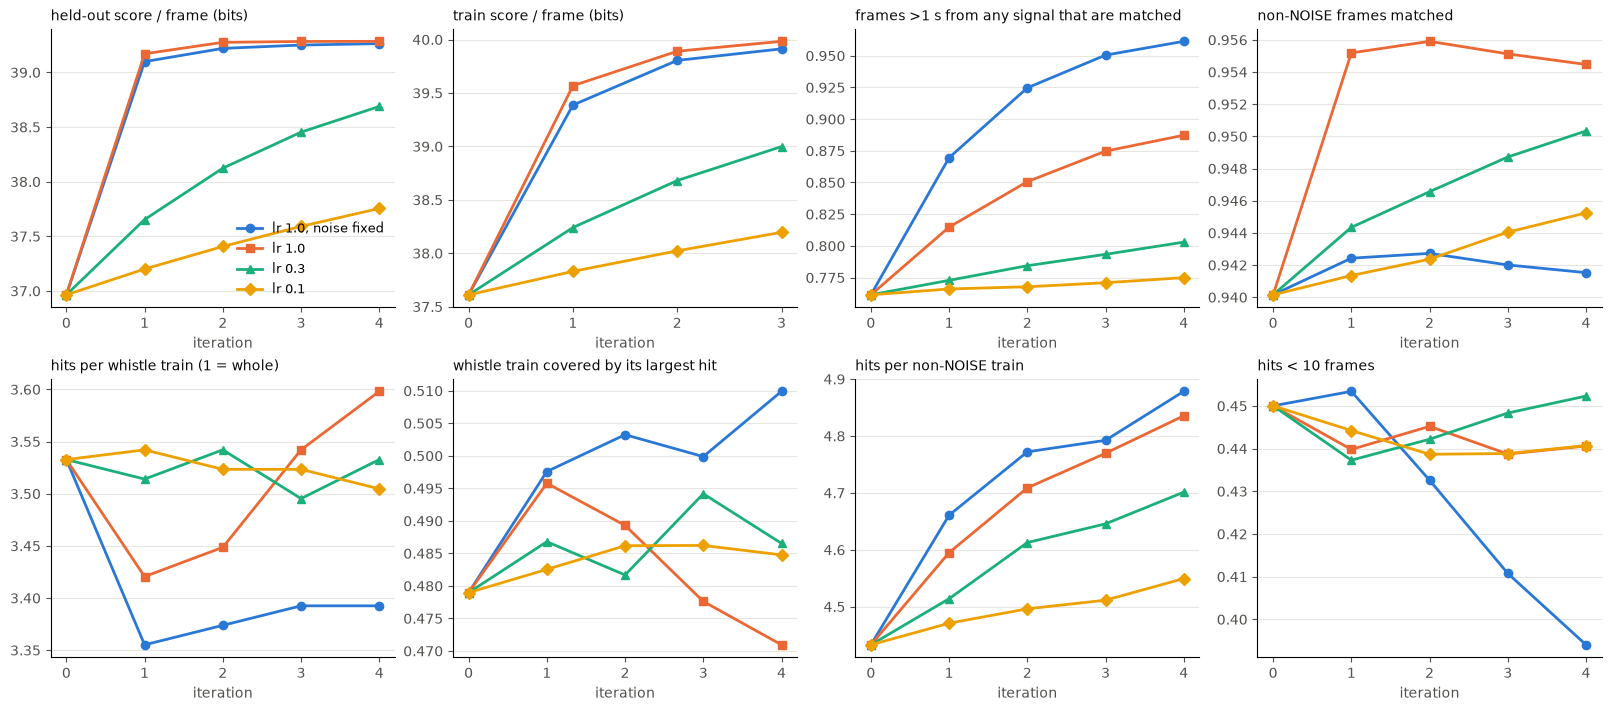

In [11]:
fig = plot_sweep(sweep)

## Before / after examples

The same held-out whistle trains decoded by the original model and a trained one. Each figure shows:

1. The spectrogram of the window, read from the recording under `AUDIO_ROOT`.
2. The classifier's per-frame labels.
3. The hits each model found, labelled with sub-model id. Whistle trains are shaded light blue behind the hit rows, so you can see whether one hit spans a whole train, its gaps included.

The title gives, for the train the window is centred on, the hit count and the share covered by the largest hit, before -> after. `pick_examples` takes the trains whose decode changed most, plus a few random ones so the set isn't only dramatic cases. Below each figure is a table of the hits.

In [12]:
EXAMPLE_CONFIG = "lr 0.3"   # which trained model to compare against the original

examples = pick_examples(
    (hmm, noise_pdf), sweep_models[EXAMPLE_CONFIG],
    heldout_sequences, heldout_labels, heldout_names,
    n_changed=4, n_random=2, window=300, max_candidates=40,
)

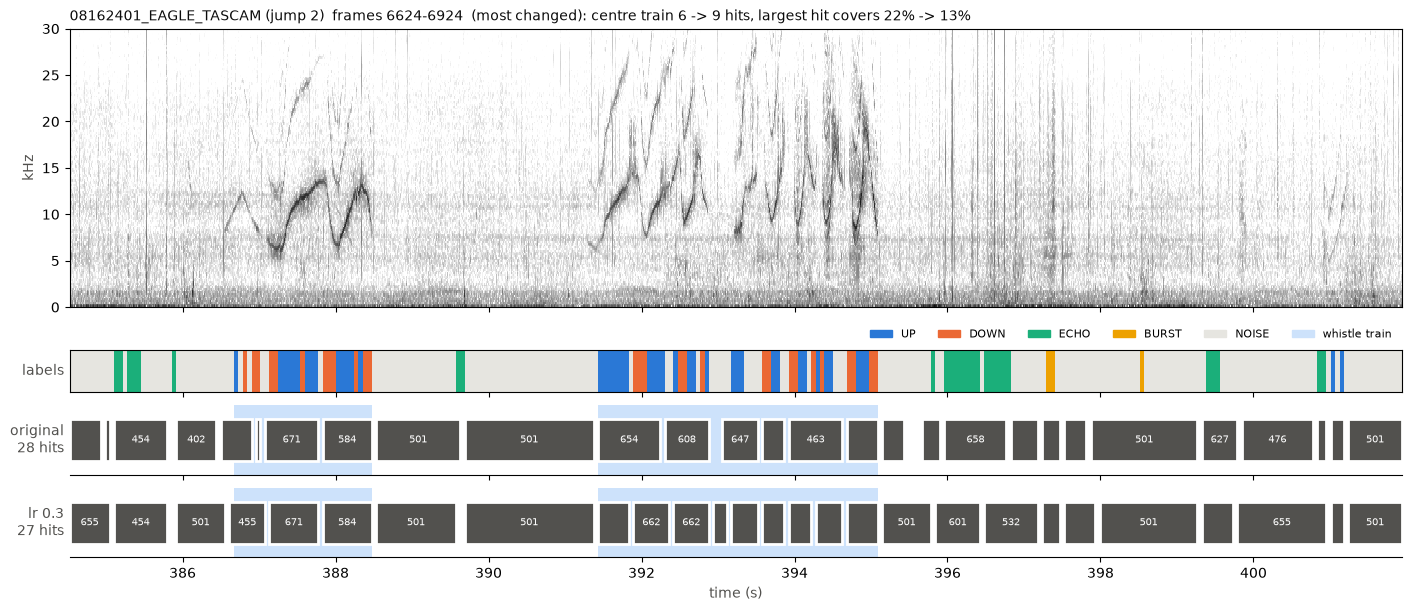

,model,start_s,stop_s,frames,submodel,majority_label,majority_fraction
0,before,384.52,384.93,7,486,NOISE,1.00
1,before,384.99,385.04,1,603,NOISE,1.00
2,before,385.10,385.80,12,454,NOISE,0.58
3,before,385.92,386.44,9,402,NOISE,1.00
4,before,386.50,386.90,7,631,NOISE,0.71
5,before,386.96,387.02,1,514,DOWN,1.00
6,before,387.08,387.77,12,671,UP,0.67
7,before,387.83,388.47,11,584,DOWN,0.55
8,before,388.53,389.63,19,501,NOISE,0.95
9,before,389.69,391.37,29,501,NOISE,1.00


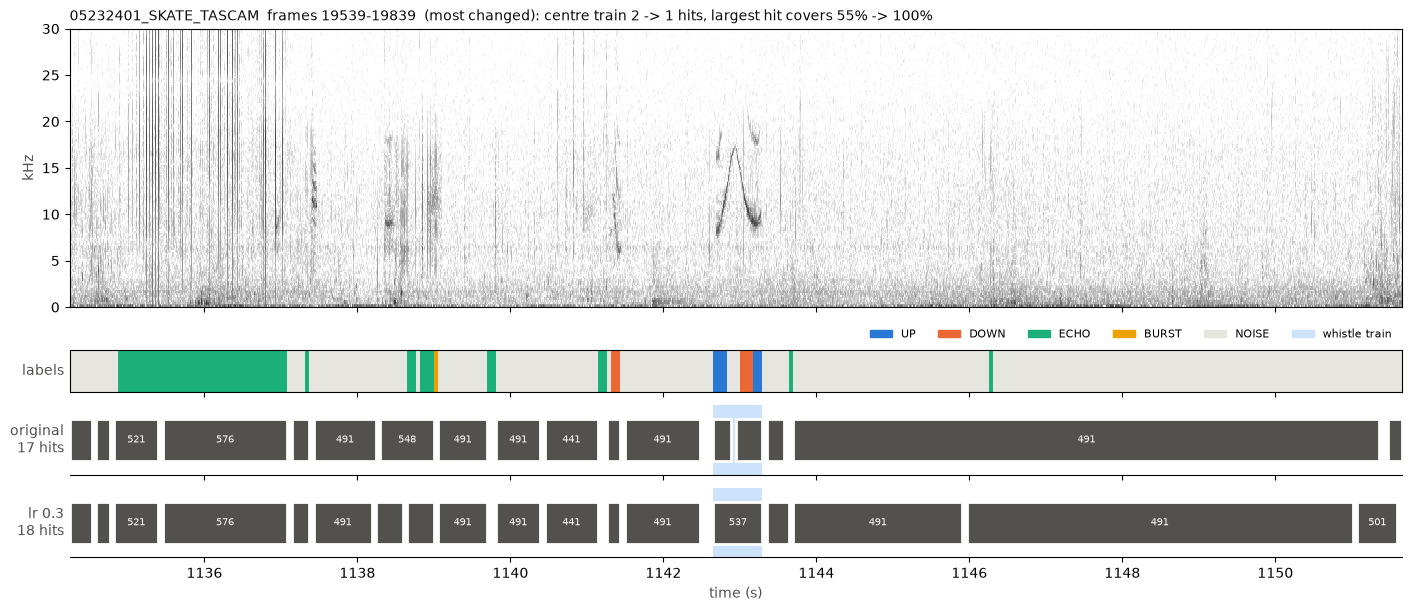

,model,start_s,stop_s,frames,submodel,majority_label,majority_fraction
0,before,1134.24,1134.53,5,441,NOISE,1.00
1,before,1134.59,1134.76,3,462,NOISE,1.00
2,before,1134.82,1135.40,10,521,ECHO,0.90
3,before,1135.46,1137.08,28,576,ECHO,1.00
4,before,1137.14,1137.37,4,543,NOISE,0.75
5,before,1137.43,1138.24,14,491,NOISE,1.00
6,before,1138.30,1139.00,12,548,NOISE,0.58
7,before,1139.05,1139.69,11,491,NOISE,1.00
8,before,1139.81,1140.39,10,491,NOISE,1.00
9,before,1140.45,1141.14,12,441,NOISE,1.00


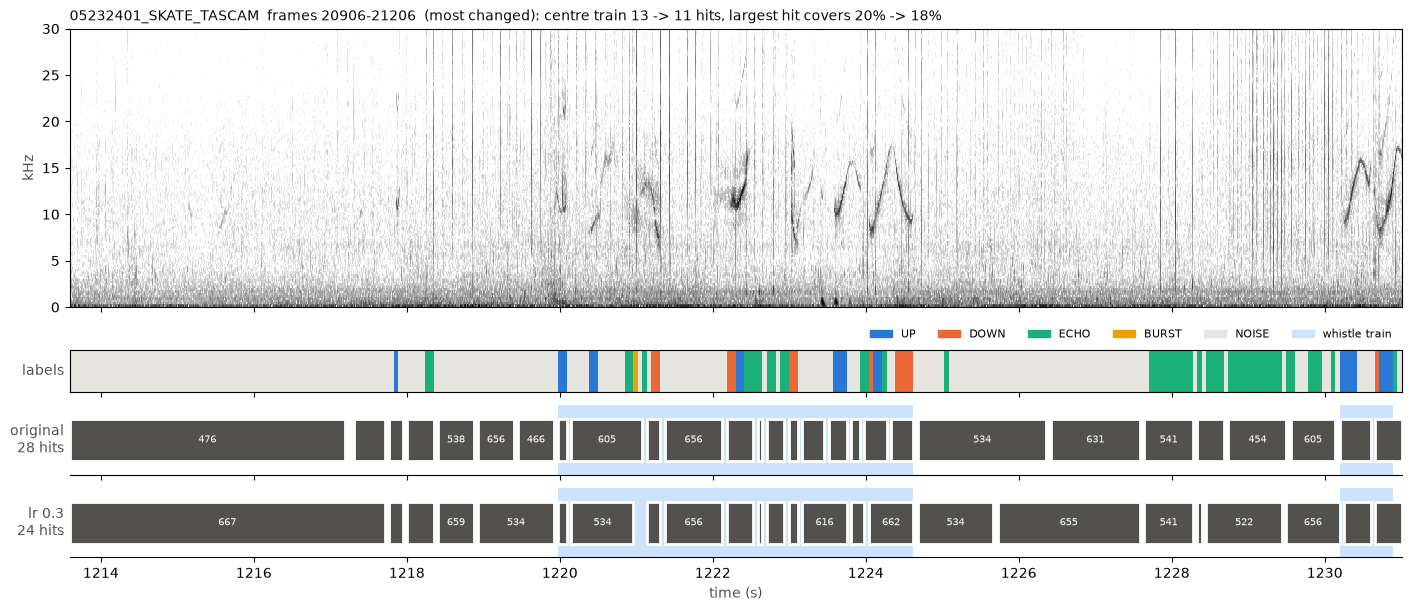

,model,start_s,stop_s,frames,submodel,majority_label,majority_fraction
0,before,1213.59,1217.19,62,476,NOISE,1.00
1,before,1217.31,1217.71,7,631,NOISE,1.00
2,before,1217.77,1217.94,3,622,NOISE,0.67
3,before,1218.00,1218.35,6,655,NOISE,0.67
4,before,1218.41,1218.87,8,538,NOISE,1.00
5,before,1218.93,1219.40,8,656,NOISE,1.00
6,before,1219.45,1219.92,8,466,NOISE,1.00
7,before,1219.98,1220.09,2,452,UP,1.00
8,before,1220.15,1221.08,16,605,NOISE,0.69
9,before,1221.14,1221.31,3,590,DOWN,0.67


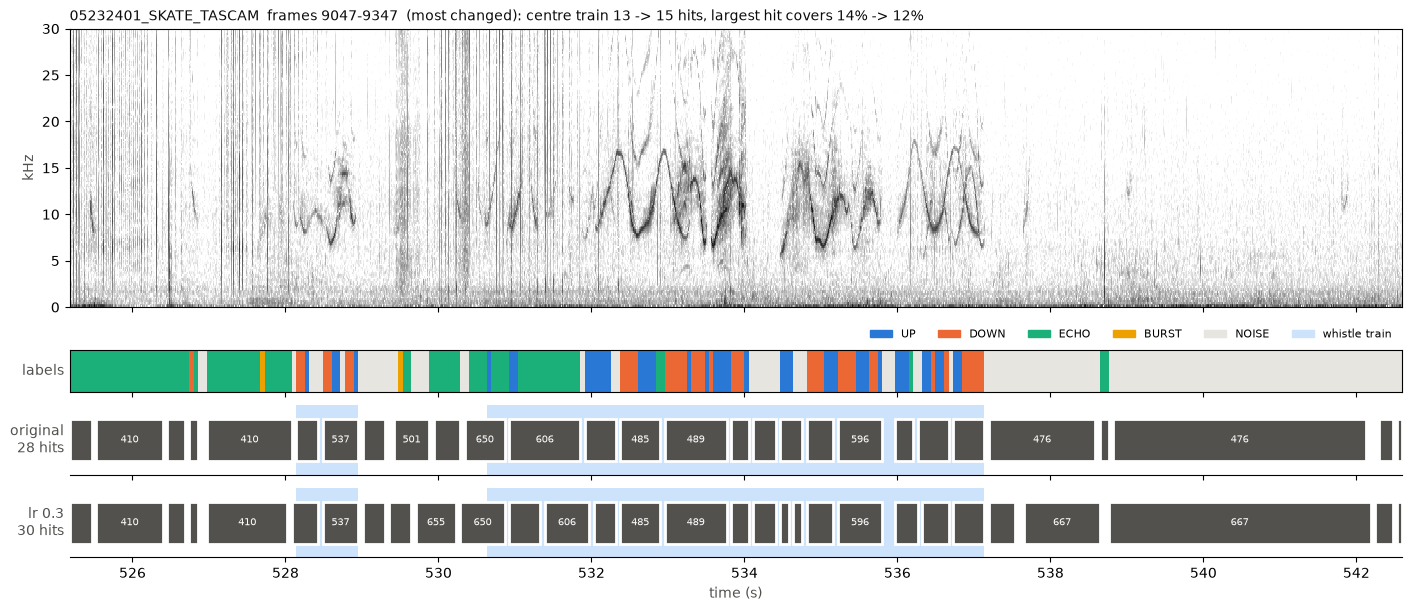

,model,start_s,stop_s,frames,submodel,majority_label,majority_fraction
0,before,525.18,525.47,5,508,ECHO,1.00
1,before,525.53,526.40,15,410,ECHO,1.00
2,before,526.45,526.69,4,407,ECHO,1.00
3,before,526.74,526.86,2,647,DOWN,0.50
4,before,526.98,528.08,19,410,ECHO,0.95
5,before,528.14,528.43,5,520,DOWN,0.40
6,before,528.49,528.95,8,537,DOWN,0.50
7,before,529.01,529.30,5,491,NOISE,1.00
8,before,529.41,529.88,8,501,NOISE,0.62
9,before,529.94,530.29,6,514,ECHO,1.00


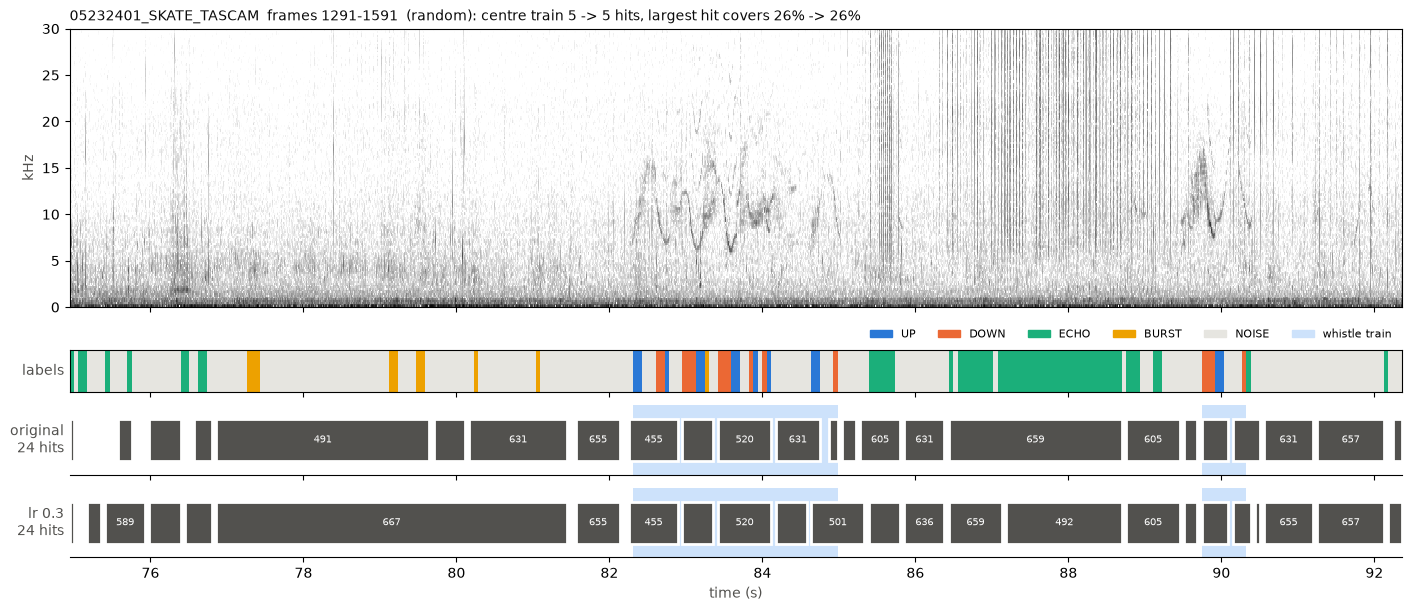

,model,start_s,stop_s,frames,submodel,majority_label,majority_fraction
0,before,74.94,75.00,1,648,ECHO,1.00
1,before,75.58,75.76,3,664,NOISE,0.67
2,before,75.99,76.39,7,631,NOISE,1.00
3,before,76.57,76.80,4,543,NOISE,0.50
4,before,76.86,79.64,48,491,NOISE,0.85
5,before,79.70,80.11,7,497,NOISE,1.00
6,before,80.17,81.44,22,631,NOISE,0.91
7,before,81.56,82.14,10,655,NOISE,1.00
8,before,82.26,82.90,11,455,NOISE,0.55
9,before,82.95,83.36,7,520,DOWN,0.43


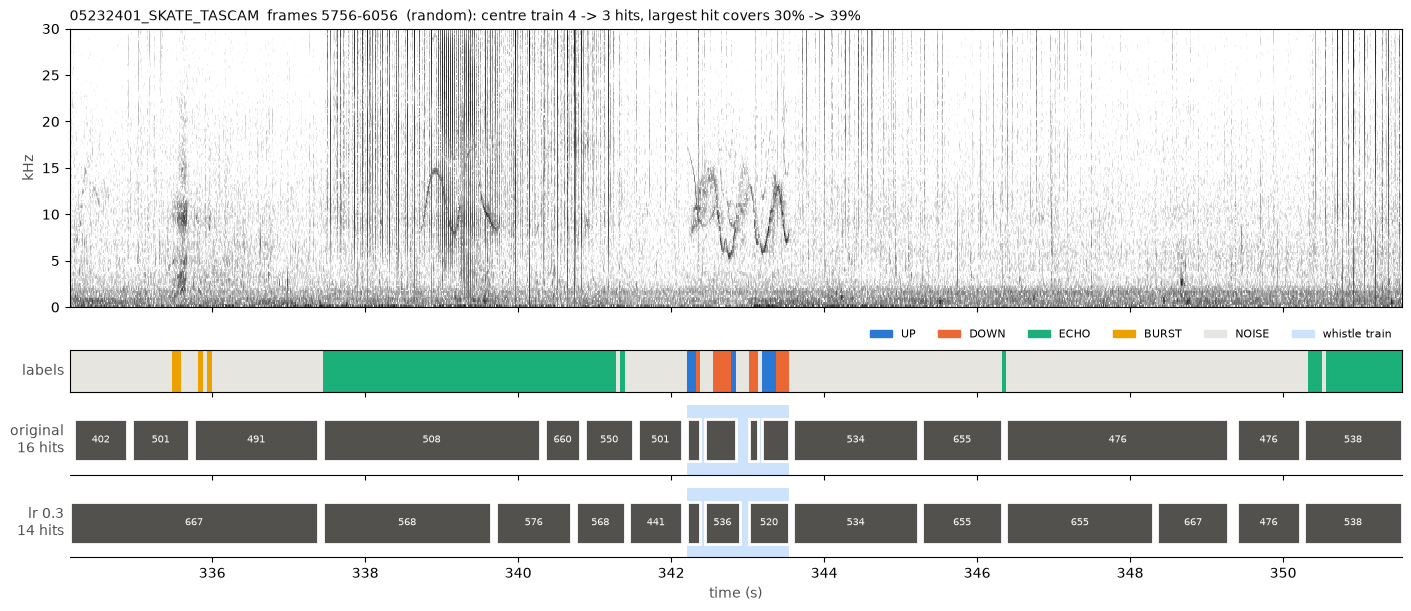

,model,start_s,stop_s,frames,submodel,majority_label,majority_fraction
0,before,334.19,334.89,12,402,NOISE,1.00
1,before,334.95,335.70,13,501,NOISE,0.85
2,before,335.76,337.39,28,491,NOISE,0.93
3,before,337.44,340.29,49,508,ECHO,1.00
4,before,340.35,340.81,8,660,ECHO,1.00
5,before,340.87,341.51,11,550,ECHO,0.73
6,before,341.57,342.15,10,501,NOISE,1.00
7,before,342.20,342.38,3,654,UP,0.67
8,before,342.44,342.84,7,536,DOWN,0.57
9,before,343.02,343.13,2,537,DOWN,1.00


In [13]:
from IPython.display import display
import matplotlib.pyplot as plt

for ex in examples:
    plot_example(ex, STEP_SECONDS, audio_index.get(ex['name']), before_label="original",
                 after_label=EXAMPLE_CONFIG, fmax_hz=FMAX_HZ)
    plt.show()
    display(example_table(ex, STEP_SECONDS))